# Understanding Optical Interconnects: SerDes and the Electrical Channel
## Article 2: calculations and reproducible figures


## Contents

0. [Setup and reusable functions](#setup)
1. [Defining the electrical link and its signal](#section-1)
2. [How the physical channel distorts the waveform](#section-2)
3. [Building an operating envelope: loss, timing, and margin](#section-3)
4. [Why a single insertion-loss number is not enough](#section-4)
5. [Recovering the data: equalization and error performance](#section-5)
6. [Power, model limitations, and the next engineering decision](#section-6)
7. [Run checks, exported files, and source notes](#run-checks)

<a id="setup"></a>
## 0. Setup and reusable functions

The setup cell reports the actual Python and library versions. Figures use Matplotlib's default
color cycle, with one chart per figure. Experiment parameters are local to their numbered sections.
Section 5 creates its own seeded random generator, so earlier cells do not consume its random sequence.

Uncomment the following installation lines only if a dependency is missing. Install packages into
the notebook's active Python environment, then restart the kernel. Running the analysis itself does
not install or download anything.

In [1]:
# Required only if packages are missing from this notebook's kernel:
# %pip install numpy matplotlib
# Optional acceleration for the DFE loop:
# %pip install numba

In [2]:
from pathlib import Path
import csv
import json
import math
import platform
import warnings
from importlib.metadata import version, PackageNotFoundError

try:
    import numpy as np
    import matplotlib
    import matplotlib.pyplot as plt
    from IPython.display import Markdown, display
except ImportError as exc:
    raise ImportError(
        "Install numpy and matplotlib in this Jupyter kernel, then restart and run all cells."
    ) from exc

# Paths are relative to the kernel's working directory, so they also work locally on Windows.
OUTPUT_ROOT = Path.cwd() / "outputs"
FIGURE_DIR = OUTPUT_ROOT / "figures"
TABLE_DIR = OUTPUT_ROOT / "tables"
for folder in (OUTPUT_ROOT, FIGURE_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

USE_NUMBA = True  # Optional only; False uses the same algorithm in pure Python.

RUNTIME_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
}
for package in ("ipython", "ipykernel", "numba"):
    try:
        RUNTIME_VERSIONS[package] = version(package)
    except PackageNotFoundError:
        RUNTIME_VERSIONS[package] = "not installed"

GENERATED_FIGURES = []
GENERATED_TABLES = []


def show_table(headers, rows):
    """Display a compact Markdown table without an extra dataframe dependency."""
    def cell(value):
        return str(value).replace("|", "&#124;").replace("\n", " ")
    lines = ["| " + " | ".join(map(cell, headers)) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines.extend("| " + " | ".join(map(cell, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


def write_records(filename, rows):
    """Write nonempty dictionary records as a UTF-8 CSV."""
    if not rows:
        raise ValueError("At least one row is required.")
    path = TABLE_DIR / filename
    with path.open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    if path.name not in GENERATED_TABLES:
        GENERATED_TABLES.append(path.name)
    return path


def save_figure(fig, stem, dpi=260):
    """Export the same plot as raster PNG and editable vector SVG."""
    for extension in ("png", "svg"):
        path = FIGURE_DIR / f"{stem}.{extension}"
        fig.savefig(path, dpi=dpi, bbox_inches="tight")
        if path.name not in GENERATED_FIGURES:
            GENERATED_FIGURES.append(path.name)
    print(f"Saved figures/{stem}.png and .svg")


def amplitude_from_loss(loss_db):
    """Positive loss in dB -> dimensionless matched-reference amplitude ratio."""
    values = np.asarray(loss_db, dtype=float)
    if not np.all(np.isfinite(values)):
        raise ValueError("Loss values must be finite.")
    return 10.0 ** (-values / 20.0)


def qfunc(value: float) -> float:
    """Upper-tail probability of a zero-mean, unit-variance Gaussian."""
    return 0.5 * math.erfc(float(value) / math.sqrt(2.0))


def analytical_raw(a: float, sigma: float) -> float:
    """Exact raw BER for the stated equiprobable binary, Gaussian-noise model."""
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("sigma must be finite and positive.")
    return 0.5 * (qfunc((1-a)/sigma) + qfunc((1+a)/sigma))


def dfe_python(y: np.ndarray, a: float) -> tuple[np.ndarray, np.ndarray]:
    """Original one-tap DFE: exact known coefficient and actual decision feedback."""
    if y.ndim != 1 or y.size == 0:
        raise ValueError("y must be a nonempty one-dimensional array.")
    decisions = np.empty(y.size, dtype=np.int8)
    z = np.empty(y.size, dtype=np.float64)
    z[0] = y[0]  # No previous decision is available at initialization.
    previous_decision = 1 if z[0] >= 0.0 else -1
    decisions[0] = previous_decision
    # Keep the prior decision as a scalar to avoid slow NumPy scalar promotion.
    # This retains the original recurrence and its floating-point operation order.
    for n in range(1, y.size):
        sample = float(y[n]) - a * previous_decision
        z[n] = sample
        previous_decision = 1 if sample >= 0.0 else -1
        decisions[n] = previous_decision
    return z, decisions


def count_errors(decisions, symbols, warmup):
    """Count scored decision errors, explicitly excluding the warm-up interval."""
    if decisions.shape != symbols.shape:
        raise ValueError("Decisions and symbols must have identical shapes.")
    if not 0 <= warmup < symbols.size:
        raise ValueError("warmup must leave at least one scored symbol.")
    return int(np.count_nonzero(decisions[warmup:] != symbols[warmup:]))


# Optional compiled loop. An unavailable/incompatible Numba installation is not fatal.
dfe = dfe_python
DFE_ENGINE = "pure Python"
if USE_NUMBA:
    try:
        from numba import njit
        candidate = njit(dfe_python)
        candidate(np.array([1.0, -0.6, 0.6]), 0.4)
        dfe = candidate
        DFE_ENGINE = "Numba acceleration"
    except Exception as exc:
        print(f"Optional Numba unavailable; using pure Python ({type(exc).__name__}).")

print("Python:", RUNTIME_VERSIONS["python"])
print("NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)
print("DFE implementation:", DFE_ENGINE)
print("Output folder: outputs/ (relative to this kernel's working directory)")

Python: 3.12.7
NumPy: 1.26.4 | Matplotlib: 3.9.2
DFE implementation: Numba acceleration
Output folder: outputs/ (relative to this kernel's working directory)


<a id="section-1"></a>
## 1. Defining the electrical link and its signal

For these amplitude signaling examples, $R_b=R_s\log_2 M$, $T_{\mathrm{UI}}=1/R_s$,
and $f_{\mathrm{N}}=R_s/2$. We use the same hypothetical **100 Gb/s transmitted bit rate**
for NRZ and PAM4; coding and error-correction overhead are omitted.
The Nyquist value is a signaling reference, not a complete waveform spectrum or a bandwidth qualification.

In [3]:
S1_BIT_RATE = 100e9  # Transmitted bits/s, not an Ethernet payload-rate claim.
s1_rows = []
for format_name, levels in (("NRZ", 2), ("PAM4", 4)):
    bits_per_symbol = math.log2(levels)
    symbol_rate = S1_BIT_RATE / bits_per_symbol
    s1_rows.append({
        "format": format_name,
        "transmitted_Gbps": S1_BIT_RATE / 1e9,
        "bits_per_symbol": bits_per_symbol,
        "symbol_rate_Gbaud": symbol_rate / 1e9,
        "symbol_period_ps": 1e12 / symbol_rate,
        "nyquist_reference_GHz": symbol_rate / 2e9,
    })
show_table(
    ["Format", "Gb/s", "Bits/symbol", "Gbaud", "UI (ps)", "Nyquist (GHz)"],
    [[r["format"], f'{r["transmitted_Gbps"]:g}', f'{r["bits_per_symbol"]:g}',
      f'{r["symbol_rate_Gbaud"]:g}', f'{r["symbol_period_ps"]:g}',
      f'{r["nyquist_reference_GHz"]:g}'] for r in s1_rows],
)
write_records("section1_rate_comparison.csv", s1_rows)
np.testing.assert_allclose(s1_rows[1]["symbol_rate_Gbaud"], S1_BIT_RATE / 2e9)
np.testing.assert_allclose(s1_rows[1]["symbol_period_ps"], 2e12 / S1_BIT_RATE)

| Format | Gb/s | Bits/symbol | Gbaud | UI (ps) | Nyquist (GHz) |
| --- | --- | --- | --- | --- | --- |
| NRZ | 100 | 1 | 100 | 10 | 50 |
| PAM4 | 100 | 2 | 50 | 20 | 25 |

At the article default, PAM4 carries 2 bits/symbol, so 100 Gb/s corresponds to **50 Gbaud**, a
**20 ps UI**, and a **25 GHz Nyquist reference**. NRZ at the same bit rate has a 10 ps UI.
For the same overall voltage span, four levels are more closely spaced than two; the rate arithmetic
is not an assertion that PAM4 improves every aspect of receiver margin.

<a id="section-2"></a>
## 2. How the physical channel distorts the waveform

### Loss conversion and the normalized binary example

For matched-reference amplitude ratios, $IL=-20\log_{10}|H|$. The separate **12 dB** example
therefore has $|H|=10^{-12/20}$. This does not determine the post-cursor coefficient below.

We reproduce the existing fixed symbol sequence and assume
$y[n]=x[n]+0.4x[n-1]$, with $x[n]\in\{-1,+1\}$, no added noise, and a fixed sampling phase.
The desired symbol's contribution is normalized to one. This is not a passive-channel gain claim.

In [4]:
S2_A = 0.4
S2_LOSS_DB = 12.0
s2_x = np.array([-1, -1, 1, 1, -1, 1, -1, -1, 1, 1, 1, -1, 1, 1, -1, -1], dtype=float)
s2_initial_previous_symbol = -1.0

if s2_x.ndim != 1 or s2_x.size == 0 or not np.all(np.isin(s2_x, [-1.0, 1.0])):
    raise ValueError("The sequence must contain only -1 and +1.")
if not np.isfinite(S2_A) or not 0 <= S2_A < 1:
    raise ValueError("This noise-free example assumes 0 <= a < 1.")
if s2_initial_previous_symbol not in (-1.0, 1.0):
    raise ValueError("The initial previous symbol must be -1 or +1.")

s2_previous = np.r_[s2_initial_previous_symbol, s2_x[:-1]]
s2_y = s2_x + S2_A * s2_previous
s2_convolution = np.convolve(
    np.r_[s2_initial_previous_symbol, s2_x], [1.0, S2_A]
)[1:s2_x.size + 1]
np.testing.assert_allclose(s2_y, s2_convolution)
np.testing.assert_array_equal(np.where(s2_y >= 0, 1.0, -1.0), s2_x)

# Match Table 2's row order in the manuscript.
s2_pairs = np.array([[1, 1], [-1, 1], [1, -1], [-1, -1]], dtype=float)
s2_case_y = s2_pairs[:, 1] + S2_A * s2_pairs[:, 0]
s2_minimum_margin = float(np.min(np.abs(s2_case_y)))
s2_cases = [dict(previous=int(pair[0]), current=int(pair[1]), received=float(value))
            for pair, value in zip(s2_pairs, s2_case_y)]
show_table(["Previous symbol", "Current symbol", "Received sample"],
           [[f'{r["previous"]:+d}', f'{r["current"]:+d}', f'{r["received"]:+.3g}']
            for r in s2_cases])
write_records("section2_symbol_cases.csv", s2_cases)
print(f"{S2_LOSS_DB:g} dB loss: amplitude ratio = {float(amplitude_from_loss(S2_LOSS_DB)):.6f}")
print(f"Minimum distance to zero threshold: {s2_minimum_margin:.3f}")
print(f"Reduction from unit no-ISI margin: {100*(1-s2_minimum_margin):.1f}%")
print("Noise-free decision errors:", count_errors(np.where(s2_y >= 0, 1, -1), s2_x, 0))

| Previous symbol | Current symbol | Received sample |
| --- | --- | --- |
| +1 | +1 | +1.4 |
| -1 | +1 | +0.6 |
| +1 | -1 | -0.6 |
| -1 | -1 | -1.4 |

12 dB loss: amplitude ratio = 0.251189
Minimum distance to zero threshold: 0.600
Reduction from unit no-ISI margin: 40.0%
Noise-free decision errors: 0


Saved figures/figure_02_channel_memory.png and .svg


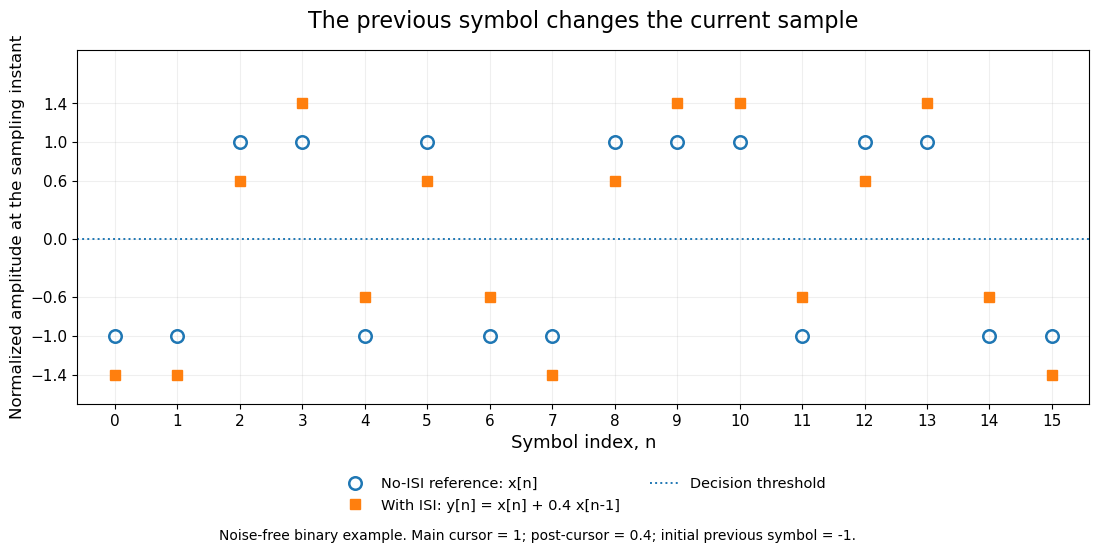

WindowsPath('C:/Users/Sourangsu/Downloads/article2_serdes/outputs/tables/figure02_samples.csv')

In [5]:
# Figure 2: markers only; no unsupported continuous-time waveform is implied.
s2_n = np.arange(s2_x.size)
fig, ax = plt.subplots(figsize=(11.5, 5.8))
ax.plot(s2_n, s2_x, linestyle="none", marker="o", markersize=9,
        fillstyle="none", markeredgewidth=1.8, label="No-ISI reference: x[n]")
ax.plot(s2_n, s2_y, linestyle="none", marker="s", markersize=6.5,
        label=f"With ISI: y[n] = x[n] + {S2_A:g} x[n-1]")
ax.axhline(0, linestyle=":", linewidth=1.4, label="Decision threshold")
ax.set_xlim(-0.6, s2_x.size - 0.4)
ax.set_ylim(-1.7, 1.95)
ax.set_xticks(s2_n)
ax.set_yticks([-1.4, -1.0, -0.6, 0.0, 0.6, 1.0, 1.4])
ax.set_xlabel("Symbol index, n", fontsize=13)
ax.set_ylabel("Normalized amplitude at the sampling instant", fontsize=12)
ax.set_title("The previous symbol changes the current sample", fontsize=16, pad=16)
ax.tick_params(labelsize=11)
ax.grid(True, alpha=0.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2,
          frameon=False, fontsize=10.5)
fig.subplots_adjust(left=0.10, right=0.98, top=0.86, bottom=0.25)
fig.text(0.5, 0.015,
         f"Noise-free binary example. Main cursor = 1; post-cursor = {S2_A:g}; initial previous symbol = {s2_initial_previous_symbol:g}.",
         ha="center", fontsize=10)
save_figure(fig, "figure_02_channel_memory", dpi=240)
plt.show()
plt.close(fig)
write_records("figure02_samples.csv", [
    dict(symbol_index=int(n), transmitted=float(x), previous=float(p), received=float(y))
    for n, x, p, y in zip(s2_n, s2_x, s2_previous, s2_y)
])

**Interpretation.** At $a=0.4$, two transmitted levels produce four possible received sample values:
$-1.4,-0.6,+0.6,+1.4$. This is binary ISI, not PAM4. The minimum threshold distance decreases from
1 to 0.6, even though the largest peak grows to 1.4. All decisions remain correct in this noise-free example.
These are discrete samples at a fixed phase, not an eye diagram or a jitter-tolerance calculation.

<a id="section-3"></a>
## 3. Building an operating envelope: loss, timing, and margin

### The article's illustrative loss allocation

All losses below refer to the **same specified frequency**, 25 GHz in this example.
Adding isolated losses is a first-order allocation for consistently referenced, sufficiently well-matched
segments. It is not a replacement for complex network cascading when inter-segment reflections matter.
The 4 dB reserve is unused allowance, not another attenuating component.
The article's existing operating-envelope and budget drawings remain static illustrations.

In [6]:
S3_REFERENCE_GHZ = 25.0
S3_BUDGET_DB = 20.0
s3_components = {
    "Tx package": 2.0,
    "PCB / channel": 10.0,
    "Vias / connectors": 2.0,
    "Rx package": 2.0,
}
s3_path_db = sum(s3_components.values())
s3_reserve_db = S3_BUDGET_DB - s3_path_db
s3_loss_rows = [dict(item=name, loss_or_allowance_dB=value, kind="physical path allocation")
                for name, value in s3_components.items()]
s3_loss_rows += [
    dict(item="Allocated path total", loss_or_allowance_dB=s3_path_db, kind="sum of physical allocations"),
    dict(item="Reserve", loss_or_allowance_dB=s3_reserve_db, kind="unused allowance, not attenuation"),
    dict(item="Total budget", loss_or_allowance_dB=S3_BUDGET_DB, kind="hypothetical limit"),
]
show_table(["Item", "dB", "Meaning"],
           [[r["item"], f'{r["loss_or_allowance_dB"]:g}', r["kind"]] for r in s3_loss_rows])
write_records("section3_loss_allocation.csv", s3_loss_rows)

s3_revised = dict(s3_components)
s3_revised["PCB / channel"] = 12.0
s3_revised_path_db = sum(s3_revised.values())
s3_revised_reserve_db = S3_BUDGET_DB - s3_revised_path_db
print(f"At {S3_REFERENCE_GHZ:g} GHz: path {s3_path_db:g} dB + reserve {s3_reserve_db:g} dB = budget {S3_BUDGET_DB:g} dB.")
print(f"Revising the PCB to 12 dB gives path {s3_revised_path_db:g} dB and reserve {s3_revised_reserve_db:g} dB.")
assert np.isclose(s3_path_db + s3_reserve_db, S3_BUDGET_DB)

| Item | dB | Meaning |
| --- | --- | --- |
| Tx package | 2 | physical path allocation |
| PCB / channel | 10 | physical path allocation |
| Vias / connectors | 2 | physical path allocation |
| Rx package | 2 | physical path allocation |
| Allocated path total | 16 | sum of physical allocations |
| Reserve | 4 | unused allowance, not attenuation |
| Total budget | 20 | hypothetical limit |

At 25 GHz: path 16 dB + reserve 4 dB = budget 20 dB.
Revising the PCB to 12 dB gives path 18 dB and reserve 2 dB.


### Timing normalization is a different calculation

We express the same **5 ps timing displacement** as a fraction of a symbol period at two symbol rates.
This is normalization, not an RMS-to-peak-to-peak conversion, a complete jitter budget, or an eye-width estimate.
The original Post 5 jitter sketch communicates this same scale comparison.

In [7]:
S3_TIMING_PS = 5.0
s3_timing_rows = []
for symbol_rate_gbaud in (50.0, 100.0):
    ui_ps = 1e3 / symbol_rate_gbaud
    s3_timing_rows.append(dict(
        symbol_rate_Gbaud=symbol_rate_gbaud, UI_ps=ui_ps,
        timing_ps=S3_TIMING_PS, timing_UI=S3_TIMING_PS/ui_ps,
    ))
show_table(["Symbol rate (Gbaud)", "UI (ps)", "Displacement (ps)", "Displacement (UI)"],
           [[f'{r[k]:g}' for k in r] for r in s3_timing_rows])
write_records("section3_timing_normalization.csv", s3_timing_rows)
assert np.isclose(s3_timing_rows[1]["timing_UI"], 2*s3_timing_rows[0]["timing_UI"])

| Symbol rate (Gbaud) | UI (ps) | Displacement (ps) | Displacement (UI) |
| --- | --- | --- | --- |
| 50 | 20 | 5 | 0.25 |
| 100 | 10 | 5 | 0.5 |

<a id="section-4"></a>
## 4. Why a single insertion-loss number is not enough

Both illustrative channels have **20 dB positive insertion loss at 25 GHz**. At the chosen
15 GHz comparison point, Channel A has 10 dB and Channel B has 30 dB. These are the assumptions
already used in Section 4, not values digitized from the hand-drawn Post 6 figure.

For a deliberately idealized inverse $G=1/H$, with equal input noise PSD **added after the channel,
before the equalizer**, the noise PSD multiplier is $1/|H|^2$.
This is a frequency-specific calculation, not a total-noise or BER prediction.

In [8]:
S4_F_REF_GHZ = 25.0
S4_F_NOTCH_GHZ = 15.0
S4_IL_REF_DB = 20.0
S4_IL_A_AT_NOTCH_DB = 10.0
S4_EXTRA_NOTCH_DB = 20.0
S4_NOTCH_HALF_WIDTH_GHZ = 5.0

if not (0 < S4_F_NOTCH_GHZ < S4_F_REF_GHZ):
    raise ValueError("The notch must be positive and below the reference frequency.")
if not (0 < S4_IL_A_AT_NOTCH_DB < S4_IL_REF_DB):
    raise ValueError("The baseline notch-frequency loss must lie below the reference loss.")
if not (0 < S4_NOTCH_HALF_WIDTH_GHZ < min(S4_F_NOTCH_GHZ, S4_F_REF_GHZ-S4_F_NOTCH_GHZ)):
    raise ValueError("The notch support must exclude DC and the reference frequency.")
if S4_EXTRA_NOTCH_DB < 0:
    raise ValueError("Extra notch attenuation must be nonnegative.")

s4_loss = np.array([S4_IL_A_AT_NOTCH_DB, S4_IL_A_AT_NOTCH_DB+S4_EXTRA_NOTCH_DB])
s4_magnitude = amplitude_from_loss(s4_loss)
s4_inverse_gain = 1.0/s4_magnitude
s4_noise_psd_gain = s4_inverse_gain**2
s4_rows = []
for i, name in enumerate(("A", "B")):
    s4_rows.append(dict(channel=name, frequency_GHz=S4_F_NOTCH_GHZ,
                        insertion_loss_dB=float(s4_loss[i]), magnitude=float(s4_magnitude[i]),
                        inverse_amplitude_gain=float(s4_inverse_gain[i]),
                        noise_PSD_multiplier=float(s4_noise_psd_gain[i])))
show_table([f"Quantity at {S4_F_NOTCH_GHZ:g} GHz", "Channel A", "Channel B"], [
    ["Assumed insertion loss (dB)", *[f"{v:g}" for v in s4_loss]],
    ["Channel amplitude magnitude", *[f"{v:.6g}" for v in s4_magnitude]],
    ["Inverse amplitude gain", *[f"{v:.6g}" for v in s4_inverse_gain]],
    ["Noise PSD multiplier", *[f"{v:.6g}" for v in s4_noise_psd_gain]],
])
write_records("section4_inverse_gain_comparison.csv", s4_rows)
print(f"Both amplitudes at {S4_F_REF_GHZ:g} GHz: {float(amplitude_from_loss(S4_IL_REF_DB)):.6g}")
print(f"Channel B / A output-noise-PSD ratio at {S4_F_NOTCH_GHZ:g} GHz: {s4_noise_psd_gain[1]/s4_noise_psd_gain[0]:.6g}")
np.testing.assert_allclose(s4_noise_psd_gain[1]/s4_noise_psd_gain[0], 10**(S4_EXTRA_NOTCH_DB/10))

| Quantity at 15 GHz | Channel A | Channel B |
| --- | --- | --- |
| Assumed insertion loss (dB) | 10 | 30 |
| Channel amplitude magnitude | 0.316228 | 0.0316228 |
| Inverse amplitude gain | 3.16228 | 31.6228 |
| Noise PSD multiplier | 10 | 1000 |

Both amplitudes at 25 GHz: 0.1
Channel B / A output-noise-PSD ratio at 15 GHz: 100


### Supplemental magnitude-only plot

The smooth baseline is $IL_A(f)=20(f/25)^p$, where $p$ makes $IL_A(15)=10$ dB.
A compact cosine-squared bump adds 20 dB of loss at 15 GHz and zero extra loss outside 10-20 GHz.
The plot uses **signed transmission**, $20\log_{10}|H|=-IL$, matching the sign convention of Post 6.
A transmission notch therefore points downward.

This construction is retained from the Section 4 notebook. It supplies no phase or physical
impedance network, so we do not infer an impulse response, eye diagram, or BER from it.
It is a numerical counterpart to the reused sketch, not a replacement for measured channel data.

Saved figures/section4_synthetic_channel_comparison.png and .svg


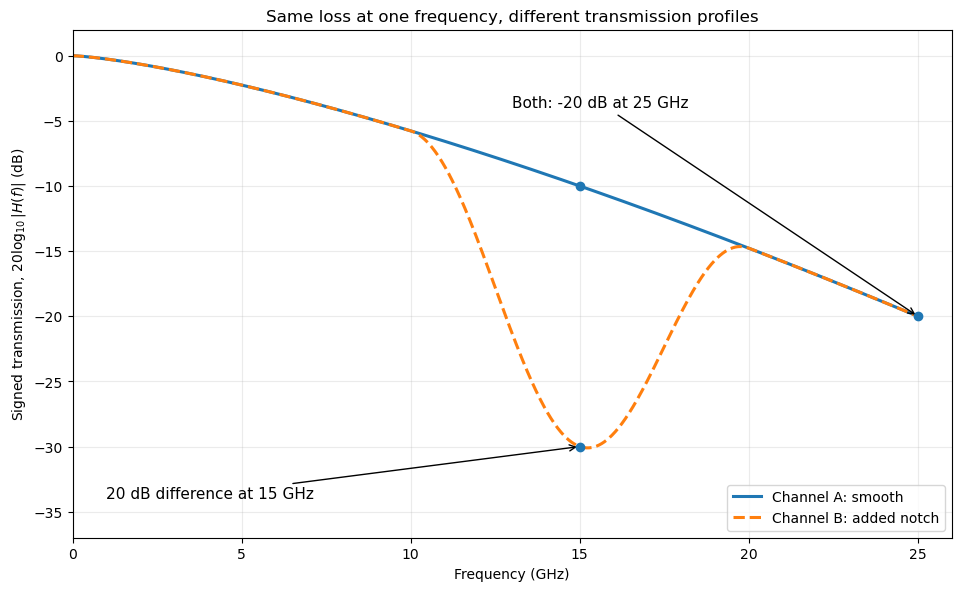

WindowsPath('C:/Users/Sourangsu/Downloads/article2_serdes/outputs/tables/section4_assumed_magnitude_profiles.csv')

In [9]:
s4_exponent = np.log(S4_IL_A_AT_NOTCH_DB/S4_IL_REF_DB) / np.log(S4_F_NOTCH_GHZ/S4_F_REF_GHZ)


def section4_illustrative_losses(f_ghz):
    """Return the article's assumed loss profiles, not physical S-parameters."""
    f_ghz = np.asarray(f_ghz, dtype=float)
    if np.any(~np.isfinite(f_ghz)) or np.any(f_ghz < 0):
        raise ValueError("Frequencies must be finite and nonnegative.")
    il_a = S4_IL_REF_DB * (f_ghz/S4_F_REF_GHZ)**s4_exponent
    offset = (f_ghz-S4_F_NOTCH_GHZ)/S4_NOTCH_HALF_WIDTH_GHZ
    bump = np.where(np.abs(offset) < 1.0, np.cos(np.pi*offset/2.0)**2, 0.0)
    return il_a, il_a + S4_EXTRA_NOTCH_DB*bump


s4_f = np.unique(np.r_[np.linspace(0.0, S4_F_REF_GHZ, 1001), S4_F_NOTCH_GHZ, S4_F_REF_GHZ])
s4_il_a, s4_il_b = section4_illustrative_losses(s4_f)
s4_a_check, s4_b_check = section4_illustrative_losses([S4_F_NOTCH_GHZ, S4_F_REF_GHZ])
np.testing.assert_allclose(s4_a_check, [S4_IL_A_AT_NOTCH_DB, S4_IL_REF_DB], atol=1e-10)
np.testing.assert_allclose(s4_b_check, [S4_IL_A_AT_NOTCH_DB+S4_EXTRA_NOTCH_DB, S4_IL_REF_DB], atol=1e-10)

fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)
ax.plot(s4_f, -s4_il_a, linewidth=2.2, label="Channel A: smooth")
ax.plot(s4_f, -s4_il_b, linewidth=2.2, linestyle="--", label="Channel B: added notch")
ax.scatter([S4_F_NOTCH_GHZ, S4_F_NOTCH_GHZ, S4_F_REF_GHZ],
           [-s4_loss[0], -s4_loss[1], -S4_IL_REF_DB], marker="o", zorder=4)
ax.annotate(f"Both: -{S4_IL_REF_DB:g} dB at {S4_F_REF_GHZ:g} GHz",
            xy=(S4_F_REF_GHZ, -S4_IL_REF_DB), xytext=(13, -4),
            arrowprops={"arrowstyle": "->"}, fontsize=11)
ax.annotate(f"{S4_EXTRA_NOTCH_DB:g} dB difference at {S4_F_NOTCH_GHZ:g} GHz",
            xy=(S4_F_NOTCH_GHZ, -s4_loss[1]), xytext=(1.0, -34),
            arrowprops={"arrowstyle": "->"}, fontsize=11)
ax.set(xlim=(0, 26), ylim=(-37, 2), xlabel="Frequency (GHz)",
       ylabel=r"Signed transmission, $20\log_{10}|H(f)|$ (dB)",
       title="Same loss at one frequency, different transmission profiles")
ax.grid(True, alpha=0.25)
ax.legend(loc="lower right", fontsize=10)
save_figure(fig, "section4_synthetic_channel_comparison", dpi=220)
plt.show()
plt.close(fig)
write_records("section4_assumed_magnitude_profiles.csv", [
    dict(frequency_GHz=float(f), IL_A_dB=float(a), IL_B_dB=float(b),
         transmission_A_dB=float(-a), transmission_B_dB=float(-b))
    for f, a, b in zip(s4_f, s4_il_a, s4_il_b)
])

At the default 15 GHz point, the inverse gains are approximately 3.162 and 31.623, while the noise
PSD multipliers are 10 and 1000. With equal input noise PSD, the second inverse therefore produces
100 times the output noise PSD **at that frequency**. This is not a 100-fold BER statement.
An ideal inverse is an analytical reference, not a demonstrated realizable receiver.
The sampled binary channel in Section 5 remains a separate model.

<a id="section-5"></a>
## 5. Recovering the data: equalization and error performance

We now retain the normalized binary model from Section 2 and add independent Gaussian sample noise:
$$y[n]=x[n]+a x[n-1]+w[n],\qquad a=0.4,\quad \sigma=0.3.$$

The DFE uses its **own previous detected symbol**:
$$z[n]=y[n]-a\hat{x}[n-1].$$
A separate ideal reference subtracts the true previous transmitted symbol; it is not available to
an actual receiver. For independent equiprobable symbols and the stated Gaussian noise,
$$p_{\mathrm{raw}}=\tfrac12 Q((1-a)/\sigma)+\tfrac12 Q((1+a)/\sigma),\qquad
p_{\mathrm{correct}}=Q(1/\sigma).$$

### Baseline parameters and reproducibility

The default run discards 2,000 initial symbols and scores 2,000,000 binary decisions per noise value.
The random-number calls below retain the original sequence: generate integer bits first, then generate
standardized Gaussian samples with the **same section-local generator**. Earlier notebook sections do
not alter this generator. Re-running this cell also resets it.

The article's original Table 4 counts are **22,940 raw errors, 872 ideal-reference errors, and
987 decision-directed DFE errors**. A check below reports whether this run matches those counts.
Changed parameters or a different random-number implementation must not be presented as the same run.

In [10]:
S5_A = 0.4
S5_SIGMA = 0.3
S5_N_BITS = 2_000_000
S5_WARMUP = 2_000
S5_SEED = 1
S5_SIGMAS = np.round(np.linspace(0.25, 0.50, 11), 3)

if not (0.0 <= S5_A < 0.5):
    raise ValueError("This article baseline assumes 0 <= a < 0.5.")
if not (np.isfinite(S5_SIGMA) and S5_SIGMA > 0):
    raise ValueError("sigma must be finite and positive.")
if not (isinstance(S5_N_BITS, int) and S5_N_BITS > 0 and isinstance(S5_WARMUP, int) and S5_WARMUP >= 1):
    raise ValueError("Use integer positive scored-bit and warm-up lengths.")
if np.any(~np.isfinite(S5_SIGMAS)) or np.any(S5_SIGMAS <= 0):
    raise ValueError("Every sweep noise standard deviation must be finite and positive.")

# Retain the original default_rng(1) stream and the original order of random calls.
s5_rng = np.random.default_rng(S5_SEED)
s5_x = (2*s5_rng.integers(0, 2, S5_N_BITS+S5_WARMUP)-1).astype(np.int8)
s5_unit_noise = s5_rng.normal(size=s5_x.size)
s5_previous = np.empty(s5_x.size, dtype=float)
s5_previous[0] = 0.0
s5_previous[1:] = s5_x[:-1]
s5_y_clean = s5_x.astype(float) + S5_A*s5_previous
s5_y = s5_y_clean + S5_SIGMA*s5_unit_noise

s5_z_dfe, s5_decisions_dfe = dfe(s5_y, S5_A)
s5_z_reference = s5_y - S5_A*s5_previous
np.testing.assert_allclose(s5_z_reference, s5_x+S5_SIGMA*s5_unit_noise, atol=1e-14)
s5_decisions_raw = np.where(s5_y >= 0, 1, -1)
s5_decisions_reference = np.where(s5_z_reference >= 0, 1, -1)

# Noiseless and implementation-consistency tests.
np.testing.assert_array_equal(np.where(s5_y_clean >= 0, 1, -1), s5_x)
s5_z_clean, s5_d_clean = dfe(s5_y_clean, S5_A)
np.testing.assert_allclose(s5_z_clean, s5_x, atol=1e-14)
np.testing.assert_array_equal(s5_d_clean, s5_x)
s5_z_test, s5_d_test = dfe_python(s5_y[:1000], S5_A)
np.testing.assert_allclose(s5_z_dfe[:1000], s5_z_test)
np.testing.assert_array_equal(s5_decisions_dfe[:1000], s5_d_test)

s5_summary = []
for name, decisions, theory in [
    ("No equalization", s5_decisions_raw, analytical_raw(S5_A, S5_SIGMA)),
    ("Correct-feedback reference", s5_decisions_reference, qfunc(1/S5_SIGMA)),
    ("Decision-directed DFE", s5_decisions_dfe, None),
]:
    errors = count_errors(decisions, s5_x, S5_WARMUP)
    s5_summary.append(dict(receiver=name, bits=S5_N_BITS, errors=errors,
                           ber=errors/S5_N_BITS, analytical_reference=theory))

show_table(["Receiver", "Errors", "Scored bits", "Observed BER", "Analytical reference"], [
    [r["receiver"], f'{r["errors"]:,}', f'{r["bits"]:,}', f'{r["ber"]:.8g}',
     "Not the ideal-feedback curve" if r["analytical_reference"] is None else f'{r["analytical_reference"]:.8g}']
    for r in s5_summary
])
write_records("section5_baseline_results.csv", s5_summary)

s5_scored_error = s5_decisions_dfe[S5_WARMUP:] != s5_x[S5_WARMUP:]
s5_prior_error = s5_decisions_dfe[S5_WARMUP-1:-1] != s5_x[S5_WARMUP-1:-1]
s5_consecutive_errors = int(np.count_nonzero(s5_scored_error & s5_prior_error))
print("DFE errors immediately following an incorrect decision:", s5_consecutive_errors)
print("Raw / DFE observed BER ratio:", s5_summary[0]["ber"]/s5_summary[2]["ber"]
      if s5_summary[2]["ber"] else "undefined: no DFE errors observed")

s5_default_parameters = (S5_A == 0.4 and S5_SIGMA == 0.3 and S5_N_BITS == 2_000_000
                         and S5_WARMUP == 2_000 and S5_SEED == 1)
s5_expected_counts = [22940, 872, 987]
s5_actual_counts = [r["errors"] for r in s5_summary]
s5_regression_match = None
if s5_default_parameters:
    s5_regression_match = s5_actual_counts == s5_expected_counts
    print("Article Table 4 count check:", "PASS" if s5_regression_match else "DIFFERS")
    if not s5_regression_match:
        warnings.warn("This environment's counts differ from the article baseline. Check the saved versions and RNG before updating the text.")
else:
    print("Article count check skipped: parameters differ from the published baseline.")

| Receiver | Errors | Scored bits | Observed BER | Analytical reference |
| --- | --- | --- | --- | --- |
| No equalization | 22,940 | 2,000,000 | 0.01147 | 0.011375831 |
| Correct-feedback reference | 872 | 2,000,000 | 0.000436 | 0.00042906033 |
| Decision-directed DFE | 987 | 2,000,000 | 0.0004935 | Not the ideal-feedback curve |

DFE errors immediately following an incorrect decision: 115
Raw / DFE observed BER ratio: 23.242147922998985
Article Table 4 count check: PASS


### Figure 7: Sample distributions, before and after DFE

We condition on the **actual transmitted current symbol being +1**, only to make the two distributions
easy to read. That truth label is not used by the DFE. The unequalized samples form pattern classes
centered at 0.6 and 1.4. Correct feedback brings the centers to 1.0 while leaving the additive noise;
the decision-directed distribution also contains incorrect-feedback events.

This is an amplitude histogram at a fixed sampling phase, **not an eye diagram**.

Saved figures/figure_07_dfe_sample_distributions.png and .svg


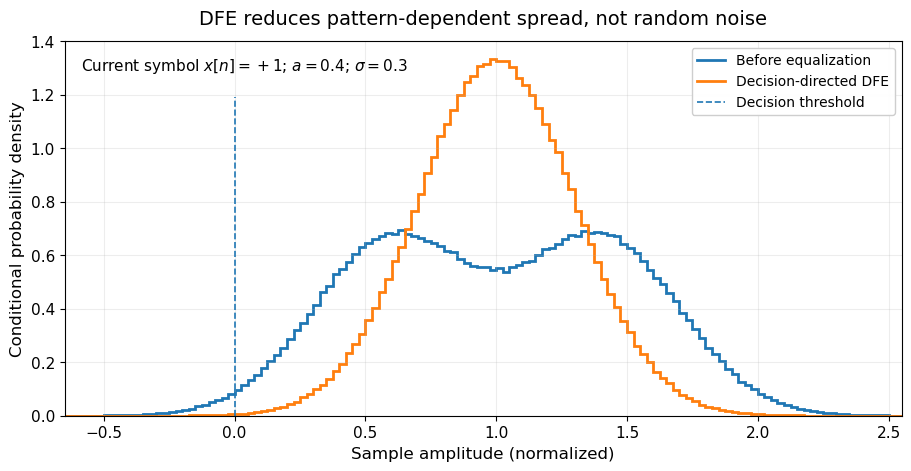

WindowsPath('C:/Users/Sourangsu/Downloads/article2_serdes/outputs/tables/figure07_histogram.csv')

In [11]:
s5_positive = s5_x[S5_WARMUP:] == 1
s5_raw_positive = s5_y[S5_WARMUP:][s5_positive]
s5_dfe_positive = s5_z_dfe[S5_WARMUP:][s5_positive]
s5_bins = np.linspace(-2.5, 3.5, 241)
for name, values in (("raw", s5_raw_positive), ("DFE", s5_dfe_positive)):
    omitted = np.count_nonzero((values < s5_bins[0]) | (values > s5_bins[-1]))
    if omitted:
        warnings.warn(f"{name}: {omitted} samples lie outside the fixed histogram bins. Widen the bins for this modified run.")
s5_raw_density, s5_edges = np.histogram(s5_raw_positive, bins=s5_bins, density=True)
s5_dfe_density, _ = np.histogram(s5_dfe_positive, bins=s5_bins, density=True)

fig, ax = plt.subplots(figsize=(9.0, 4.6), constrained_layout=True)
ax.stairs(s5_raw_density, s5_edges, linewidth=2.0, label="Before equalization")
ax.stairs(s5_dfe_density, s5_edges, linewidth=2.0, label="Decision-directed DFE")
ax.axvline(0.0, ymin=0.0, ymax=0.85, linestyle="--", linewidth=1.2, label="Decision threshold")
ax.set_xlim(-0.65, 2.55)
ax.set_ylim(bottom=0)
ax.set_xlabel("Sample amplitude (normalized)", fontsize=12)
ax.set_ylabel("Conditional probability density", fontsize=12)
ax.set_title("DFE reduces pattern-dependent spread, not random noise", fontsize=14, pad=12)
ax.text(0.02, 0.96, rf"Current symbol $x[n]=+1$; $a={S5_A:g}$; $\sigma={S5_SIGMA:g}$",
        transform=ax.transAxes, va="top", fontsize=11)
ax.tick_params(labelsize=11)
ax.grid(True, alpha=0.22)
ax.legend(loc="upper right", fontsize=10, framealpha=0.95)
save_figure(fig, "figure_07_dfe_sample_distributions")
plt.show()
plt.close(fig)
write_records("figure07_histogram.csv", [
    dict(bin_left=float(left), bin_right=float(right),
         amplitude_bin_center=float((left+right)/2), raw_density=float(raw), dfe_density=float(equalized))
    for left, right, raw, equalized in zip(s5_edges[:-1], s5_edges[1:], s5_raw_density, s5_dfe_density)
])

### Figure 8: Error rate versus sample-noise standard deviation

The sweep reuses the same data and standardized Gaussian draws at every noise level, as in the original
Section 5 notebook. This controls the comparison; the points are not statistically independent trials.
Both simulated receivers see the same received samples at each point. The dashed curve assumes
always-correct feedback and is not a practical DFE result.

The range begins at $\sigma=0.25$ so the default run retains observable error counts.
A zero-count point in a modified run is not plotted as zero on a logarithmic axis and does not establish zero BER.

sigma=0.250: raw errors=8,324, DFE errors=68
sigma=0.275: raw errors=14,741, DFE errors=312
sigma=0.300: raw errors=22,940, DFE errors=987
sigma=0.325: raw errors=32,653, DFE errors=2,444
sigma=0.350: raw errors=43,447, DFE errors=4,954
sigma=0.375: raw errors=55,194, DFE errors=8,904
sigma=0.400: raw errors=67,236, DFE errors=14,549
sigma=0.425: raw errors=79,648, DFE errors=22,022
sigma=0.450: raw errors=92,220, DFE errors=31,146
sigma=0.475: raw errors=104,900, DFE errors=41,738
sigma=0.500: raw errors=117,556, DFE errors=53,612
Saved figures/figure_08_ber_vs_noise.png and .svg


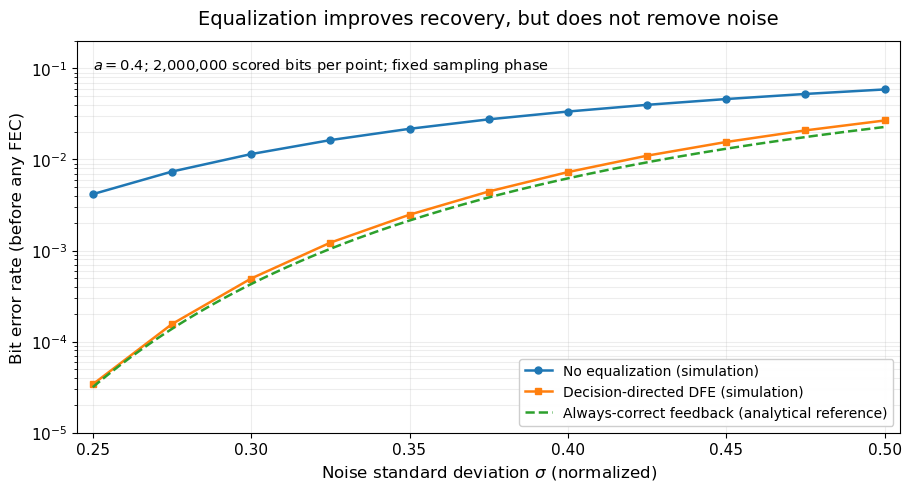

In [12]:
s5_sweep = []
for s5_sigma_value in S5_SIGMAS:
    this_y = s5_y_clean + float(s5_sigma_value)*s5_unit_noise
    this_z, this_decisions = dfe(this_y, S5_A)
    raw_count = count_errors(np.where(this_y >= 0, 1, -1), s5_x, S5_WARMUP)
    dfe_count = count_errors(this_decisions, s5_x, S5_WARMUP)
    s5_sweep.append(dict(
        sigma=float(s5_sigma_value), bits=S5_N_BITS, raw_errors=raw_count,
        dfe_errors=dfe_count, raw_ber=raw_count/S5_N_BITS, dfe_ber=dfe_count/S5_N_BITS,
        raw_analytical=analytical_raw(S5_A, float(s5_sigma_value)),
        correct_feedback_analytical=qfunc(1/float(s5_sigma_value)),
    ))
    print(f"sigma={s5_sigma_value:.3f}: raw errors={raw_count:,}, DFE errors={dfe_count:,}")

for row in s5_sweep:
    if np.isclose(row["sigma"], S5_SIGMA, atol=1e-14, rtol=0):
        assert row["raw_errors"] == s5_summary[0]["errors"]
        assert row["dfe_errors"] == s5_summary[2]["errors"]
write_records("section5_noise_sweep.csv", s5_sweep)

s5_sweep_sigmas = np.array([r["sigma"] for r in s5_sweep])
s5_raw_rates = np.array([r["raw_ber"] for r in s5_sweep])
s5_dfe_rates = np.array([r["dfe_ber"] for r in s5_sweep])
if np.any(s5_raw_rates == 0) or np.any(s5_dfe_rates == 0):
    warnings.warn("Zero-error points are omitted on the log plot; retain their counts in the CSV.")
fig, ax = plt.subplots(figsize=(9.0, 4.8), constrained_layout=True)
ax.semilogy(s5_sweep_sigmas, np.where(s5_raw_rates>0, s5_raw_rates, np.nan), "o-",
            linewidth=1.8, markersize=5, label="No equalization (simulation)")
ax.semilogy(s5_sweep_sigmas, np.where(s5_dfe_rates>0, s5_dfe_rates, np.nan), "s-",
            linewidth=1.8, markersize=5, label="Decision-directed DFE (simulation)")
s5_fine_sigma = np.linspace(s5_sweep_sigmas[0], s5_sweep_sigmas[-1], 350)
ax.semilogy(s5_fine_sigma, [qfunc(1/v) for v in s5_fine_sigma], "--", linewidth=1.8,
            label="Always-correct feedback (analytical reference)")
ax.set_xlabel(r"Noise standard deviation $\sigma$ (normalized)", fontsize=12)
ax.set_ylabel("Bit error rate (before any FEC)", fontsize=12)
ax.set_title("Equalization improves recovery, but does not remove noise", fontsize=14, pad=12)
ax.text(0.02, 0.96,
        rf"$a={S5_A:g}$; {S5_N_BITS:,} scored bits per point; fixed sampling phase",
        transform=ax.transAxes, va="top", fontsize=10.5)
ax.set_xlim(float(s5_sweep_sigmas[0])-0.005, float(s5_sweep_sigmas[-1])+0.005)
ax.set_ylim(1e-5, 0.2)
ax.grid(True, which="both", alpha=0.22)
ax.tick_params(labelsize=11)
ax.legend(loc="lower right", fontsize=10, framealpha=0.95)
save_figure(fig, "figure_08_ber_vs_noise")
plt.show()
plt.close(fig)

### Analytical check of decision-feedback error propagation

This model-specific check was included in the Section 5 notebook; it is not a general commercial-DFE formula.
Let $p_0=Q(1/\sigma)$ be the next-error probability after a correct decision. After an incorrect decision,
the residual contribution has magnitude $2a$, so
$$p_1=\tfrac12 Q((1-2a)/\sigma)+\tfrac12 Q((1+2a)/\sigma).$$
For the stated independent data/noise assumptions, the stationary error probability is
$$p=\frac{p_0}{1-p_1+p_0}.$$
This explains why actual decision feedback is slightly worse than the always-correct reference.
The article uses the simulated counts; this extra check is retained as supporting analysis.

In [13]:
def stationary_dfe_ber(a: float, sigma: float) -> float:
    """Stationary BER for this exact one-post-cursor binary model only."""
    if sigma <= 0:
        raise ValueError("sigma must be positive.")
    p0 = qfunc(1/sigma)
    p1 = 0.5*(qfunc((1-2*a)/sigma) + qfunc((1+2*a)/sigma))
    return p0/(1-p1+p0)


s5_p_raw = analytical_raw(S5_A, S5_SIGMA)
s5_p_correct = qfunc(1/S5_SIGMA)
s5_p_stationary_dfe = stationary_dfe_ber(S5_A, S5_SIGMA)
print(f"Raw analytical BER: {s5_p_raw:.10g}")
print(f"Always-correct feedback BER: {s5_p_correct:.10g}")
print(f"Stationary decision-directed BER: {s5_p_stationary_dfe:.10g}")
print(f"Simulated decision-directed BER: {s5_summary[2]['ber']:.10g}")
print("Finite-run estimates need not equal the analytical probabilities exactly.")

Raw analytical BER: 0.01137583129
Always-correct feedback BER: 0.0004290603332
Stationary decision-directed BER: 0.0004908130629
Simulated decision-directed BER: 0.0004935
Finite-run estimates need not equal the analytical probabilities exactly.


### Transmit-FFE cancellation and the peak-swing check

The handoff's two-tap transmit filter $c=[1,-0.4]$ and channel $h=[1,0.4]$ cascade to
$[1,0,-0.16]$. The first post-cursor is canceled, but the transmit signal's maximum magnitude becomes 1.4.
With the same peak-amplitude limit as the original signal, the coefficients must be divided by 1.4.
The minimum noise-free distance to the zero threshold is then $(1-0.16)/1.4=0.6$, not 0.84.
This is the same normalization check developed in the article, not a verdict on practical FFE designs.

In [14]:
s5_h = np.array([1.0, S5_A])
s5_c = np.array([1.0, -S5_A])
s5_ffe_cascade = np.convolve(s5_c, s5_h)
np.testing.assert_allclose(s5_ffe_cascade, [1.0, 0.0, -S5_A*S5_A], atol=1e-14)
s5_peak_scale = float(np.sum(np.abs(s5_c)))
s5_normalized_cascade = s5_ffe_cascade/s5_peak_scale
s5_ffe_min_distance = (1-S5_A*S5_A)/s5_peak_scale
np.testing.assert_allclose(s5_ffe_min_distance, 1-S5_A)

s5_ffe_rows = [
    dict(case="No transmit FFE", transmit_peak=1.0, main_cursor=1.0,
         first_postcursor=S5_A, second_postcursor=0.0, minimum_threshold_distance=1-S5_A),
    dict(case="Unnormalized two-tap FFE", transmit_peak=s5_peak_scale,
         main_cursor=float(s5_ffe_cascade[0]), first_postcursor=float(s5_ffe_cascade[1]),
         second_postcursor=float(s5_ffe_cascade[2]), minimum_threshold_distance=1-S5_A*S5_A),
    dict(case="Same-peak two-tap FFE", transmit_peak=1.0,
         main_cursor=float(s5_normalized_cascade[0]), first_postcursor=float(s5_normalized_cascade[1]),
         second_postcursor=float(s5_normalized_cascade[2]), minimum_threshold_distance=s5_ffe_min_distance),
]
show_table(["Case", "Tx peak", "Main cursor", "1st post-cursor", "2nd post-cursor", "Min. threshold distance"],
           [[r["case"]] + [f"{r[k]:.6g}" for k in list(r)[1:]] for r in s5_ffe_rows])
write_records("section5_ffe_normalization.csv", s5_ffe_rows)

| Case | Tx peak | Main cursor | 1st post-cursor | 2nd post-cursor | Min. threshold distance |
| --- | --- | --- | --- | --- | --- |
| No transmit FFE | 1 | 1 | 0.4 | 0 | 0.6 |
| Unnormalized two-tap FFE | 1.4 | 1 | 0 | -0.16 | 0.84 |
| Same-peak two-tap FFE | 1 | 0.714286 | 0 | -0.114286 | 0.6 |

WindowsPath('C:/Users/Sourangsu/Downloads/article2_serdes/outputs/tables/section5_ffe_normalization.csv')

### CTLE, CDR, and FEC: the boundary of the numerical results

The manuscript also describes a first CTLE model,
$H_{\mathrm{CTLE}}(s)=G_0(1+s/\omega_z)/(1+s/\omega_p)$ with $\omega_z<\omega_p$.
It distinguishes analog response shaping from timing recovery (CDR) and redundant-data error correction (FEC).
No numerical CTLE pole/zero choices, CDR loop, adaptation algorithm, or FEC code were defined in the
published examples, so none is silently added to this merged notebook. In particular, all plotted BERs
are before any FEC and are evaluated at a fixed sampling phase.

<a id="section-6"></a>
## 6. Power, model limitations, and the next engineering decision

Energy per bit is $E_{\mathrm{bit}}=P/R_b$, with a consistent accounting boundary.
Here, 1 W is an illustrative allocation for the electrical transmit/receive functions associated with
one unidirectional 100 Gb/s lane. It is not the complete optical interconnect's power.
The binary Monte Carlo model has no circuit-power model, so its BER improvement does not predict an energy saving.

In [15]:
S6_POWER_PER_LANE_W = 1.0
S6_BIT_RATE = 100e9
S6_LANES = 32
S6_SAVING_PJ_PER_BIT = 2.0

s6_energy_pj = S6_POWER_PER_LANE_W / S6_BIT_RATE * 1e12
s6_aggregate_rate_tbps = S6_LANES * S6_BIT_RATE / 1e12
s6_aggregate_power_w = S6_LANES * S6_POWER_PER_LANE_W
s6_saving_per_lane_w = S6_SAVING_PJ_PER_BIT * 1e-12 * S6_BIT_RATE
s6_total_saving_w = S6_LANES * s6_saving_per_lane_w
s6_rows = [
    dict(quantity="Allocated operating power per lane", value=S6_POWER_PER_LANE_W, unit="W"),
    dict(quantity="Transmitted rate per lane", value=S6_BIT_RATE/1e9, unit="Gb/s"),
    dict(quantity="Energy per transmitted bit", value=s6_energy_pj, unit="pJ/bit"),
    dict(quantity="Number of simultaneous lanes", value=S6_LANES, unit="lanes"),
    dict(quantity="Aggregate transmitted rate", value=s6_aggregate_rate_tbps, unit="Tb/s"),
    dict(quantity="Combined operating-power allocation", value=s6_aggregate_power_w, unit="W"),
    dict(quantity="Assumed energy reduction", value=S6_SAVING_PJ_PER_BIT, unit="pJ/bit"),
    dict(quantity="Calculated saving per lane", value=s6_saving_per_lane_w, unit="W"),
    dict(quantity="Calculated saving across all lanes", value=s6_total_saving_w, unit="W"),
]
show_table(["Quantity", "Value", "Units"], [[r["quantity"], f'{r["value"]:g}', r["unit"]] for r in s6_rows])
write_records("section6_energy_accounting.csv", s6_rows)
np.testing.assert_allclose(s6_total_saving_w, S6_LANES*s6_saving_per_lane_w)

| Quantity | Value | Units |
| --- | --- | --- |
| Allocated operating power per lane | 1 | W |
| Transmitted rate per lane | 100 | Gb/s |
| Energy per transmitted bit | 10 | pJ/bit |
| Number of simultaneous lanes | 32 | lanes |
| Aggregate transmitted rate | 3.2 | Tb/s |
| Combined operating-power allocation | 32 | W |
| Assumed energy reduction | 2 | pJ/bit |
| Calculated saving per lane | 0.2 | W |
| Calculated saving across all lanes | 6.4 | W |

### What is and is not established

The deterministic calculations and Monte Carlo experiment show the effect of a chosen channel memory,
noise level, and recovery rule. They do not establish a real interface's compliance, an ultra-low BER floor,
receiver training behavior, clock recovery, FEC performance, or a hardware energy figure.

For a physical-route decision, the next model needs the relevant complex channel response and terminations.
For a timing decision, it needs waveform and sampling-clock dynamics. For a post-FEC error target, it needs
the chosen code, decoder, and error patterns. For an energy comparison, it needs implementation power data.
These are separate modeling requirements, not missing parameters to infer from the toy channel.

<a id="run-checks"></a>
## Run checks and exported files

The final cell writes the numerical results, the actual runtime versions, and the default-parameter
regression check to JSON. Every plot also has a CSV of its underlying samples or numerical profile.
The original figure numbers are retained even though the intervening hand-drawn illustrations are not generated here.

Files are saved relative to the kernel working directory, so the notebook can be moved as a single file.
No original section notebook, PDF, document, or image file is required at runtime.

In [16]:
expected_plot_stems = [
    "figure_02_channel_memory", "section4_synthetic_channel_comparison",
    "figure_07_dfe_sample_distributions", "figure_08_ber_vs_noise",
]
for stem in expected_plot_stems:
    for extension in ("png", "svg"):
        path = FIGURE_DIR / f"{stem}.{extension}"
        if not path.is_file() or path.stat().st_size == 0:
            raise RuntimeError(f"Missing or empty figure: {path.name}")

run_summary = {
    "article": "Understanding Optical Interconnects: SerDes and the Electrical Channel",
    "runtime_versions": RUNTIME_VERSIONS,
    "dfe_engine": DFE_ENGINE,
    "section1_rate_comparison": s1_rows,
    "section2": {
        "a": S2_A, "initial_previous_symbol": s2_initial_previous_symbol,
        "loss_example_dB": S2_LOSS_DB,
        "loss_example_amplitude_ratio": float(amplitude_from_loss(S2_LOSS_DB)),
        "minimum_threshold_distance": s2_minimum_margin,
    },
    "section3": {
        "reference_frequency_GHz": S3_REFERENCE_GHZ, "total_budget_dB": S3_BUDGET_DB,
        "path_loss_dB": s3_path_db, "reserve_dB": s3_reserve_db,
        "revised_path_loss_dB": s3_revised_path_db, "revised_reserve_dB": s3_revised_reserve_db,
        "timing_normalization": s3_timing_rows,
    },
    "section4_inverse_gain_comparison": s4_rows,
    "section5": {
        "a": S5_A, "sigma": S5_SIGMA, "seed": S5_SEED,
        "scored_bits": S5_N_BITS, "warmup_symbols": S5_WARMUP,
        "random_bit_generator": type(s5_rng.bit_generator).__name__,
        "baseline": s5_summary, "noise_sweep": s5_sweep,
        "errors_after_incorrect_feedback": s5_consecutive_errors,
        "analytical_raw": s5_p_raw, "analytical_correct_feedback": s5_p_correct,
        "analytical_stationary_dfe": s5_p_stationary_dfe,
        "article_default_parameters": s5_default_parameters,
        "article_expected_counts": s5_expected_counts,
        "observed_counts": s5_actual_counts,
        "article_count_check_passed": s5_regression_match,
        "ffe_cascade": s5_ffe_cascade.tolist(),
        "ffe_peak_normalized_cascade": s5_normalized_cascade.tolist(),
        "ffe_minimum_threshold_distance": s5_ffe_min_distance,
    },
    "section6_energy_accounting": s6_rows,
    "generated_figures": GENERATED_FIGURES,
    "generated_csv_tables": GENERATED_TABLES,
}
with (OUTPUT_ROOT / "run_summary.json").open("w", encoding="utf-8") as handle:
    json.dump(run_summary, handle, indent=2)
with (OUTPUT_ROOT / "runtime_versions.json").open("w", encoding="utf-8") as handle:
    json.dump(RUNTIME_VERSIONS, handle, indent=2)

print("Completed all six sections.")
print("Verified 4 plots, each exported as PNG and SVG.")
print(f"Saved {len(GENERATED_TABLES)} CSV tables and 2 JSON records.")
print("Default Table 4 count match:", s5_regression_match)
print("Outputs: outputs/figures/, outputs/tables/, and outputs/*.json")

Completed all six sections.
Verified 4 plots, each exported as PNG and SVG.
Saved 12 CSV tables and 2 JSON records.
Default Table 4 count match: True
Outputs: outputs/figures/, outputs/tables/, and outputs/*.json
